<a href="https://colab.research.google.com/github/MankotiaGit/Statistical-Foundation-of-Data-Sciences-/blob/main/SFDS_PRACTICAL_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Import the required libraries, including numpy, pandas, matplotlib, seaborn, and scikit-learn.


Step 2: Set the visualization style using seaborn.


Step 3: Load the built-in wine dataset using load_wine().


Step 4: Convert the dataset into a pandas dataframe with appropriate feature names.


Step 5: Add target labels and wine class names to the dataframe.


Step 6: Store all feature names for further analysis.


Step 7: Display the first five rows of the dataset using df.head().


Step 8: Check the number of rows and columns using df.shape.


Step 9: Count the number of samples belonging to each wine class.


Step 10: Calculate descriptive statistics such as mean, standard deviation, minimum, and maximum.


Step 11: Create boxplots to compare the distribution of each feature across wine classes.


Step 12: Identify possible outliers and differences in feature distributions using boxplots.


Step 13: Create a scatter plot to visualize the relationship between flavanoids and proline.


Step 14: Calculate the covariance matrix of the original features.


Step 15: Visualize the covariance matrix using a heatmap.


Step 16: Standardize the features using StandardScaler.


Step 17: Create a new dataframe containing the standardized feature values.


Step 18: Display the statistical summary of the standardized data to verify scaling.


Step 19: Calculate and visualize the covariance matrix of the standardized features.


Step 20: Apply principal component analysis (PCA) to reduce the dataset to two principal components.


Step 21: Calculate and display the explained variance ratio of PC1 and PC2.


Step 22: Calculate the total percentage of variance explained by the two principal components.


Step 23: Create a new dataframe containing PC1, PC2, and the corresponding wine class labels.


Step 24: Plot the original features (alcohol and malic acid) to compare wine classes.


Step 25: Plot PC1 against PC2 to visualize the wine classes after dimensionality reduction.


Step 26: Display the percentage of variance explained by each principal component on the plot axes.


Step 27: Apply PCA to all standardized features to calculate the explained variance of every component.


Step 28: Calculate the cumulative explained variance for all principal components.


Step 29: Plot cumulative explained variance against the number of components.


Step 30: Analyze the plots to understand how PCA reduces dimensionality while retaining important information and helps visualize differences between wine classes.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Imports libraries for numerical calculations, data analysis, and visualization.
Loads the Wine dataset and standardizes features using StandardScaler.
Uses PCA to reduce features while preserving important information.

In [17]:
sns.set_style('whitegrid')

wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['target'] = wine.target
df['class'] = df['target'].map(dict(enumerate(wine.target_names)))
features = wine.feature_names

Sets the graph style to a white background with grid lines.
Loads the Wine dataset and converts it into a Pandas DataFrame with feature names.
Adds target labels and class names to identify the three wine categories.

In [18]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


Displays the first five rows of the DataFrame to preview the Wine dataset.

1 Basic statistics

In [19]:
print('Shape:', df.shape)
print('\nClass counts:\n', df['class'].value_counts())
df[features].describe().T

Shape: (178, 15)

Class counts:
 class
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Prints the dataset’s dimensions (rows and columns) and the number of samples in each wine class.
Displays descriptive statistics (mean, standard deviation, minimum, maximum, etc.) for all features.

2 Boxplots by class

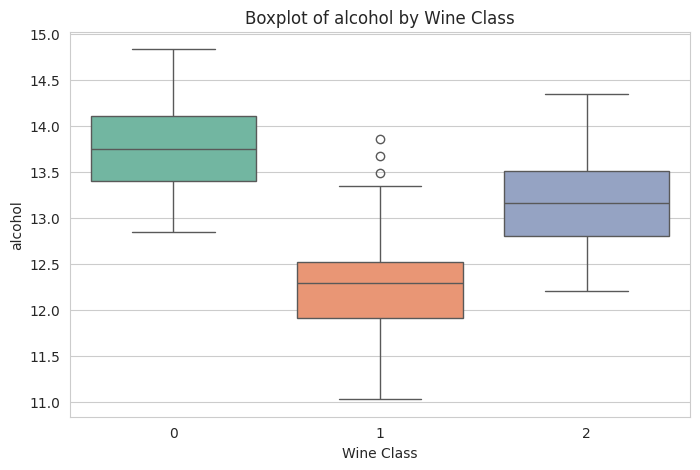

In [20]:
feature = "alcohol"

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="target", y=feature, hue="target", palette="Set2", legend=False)
plt.title(f"Boxplot of {feature} by Wine Class")
plt.xlabel("Wine Class")
plt.ylabel(feature)
plt.show()

Selected the alcohol feature to compare its distribution across the three wine classesand also created a boxplot using different colours to show the median, spread, and outliers of alcohol content in each wine class.

3 Scatterplot using two variables

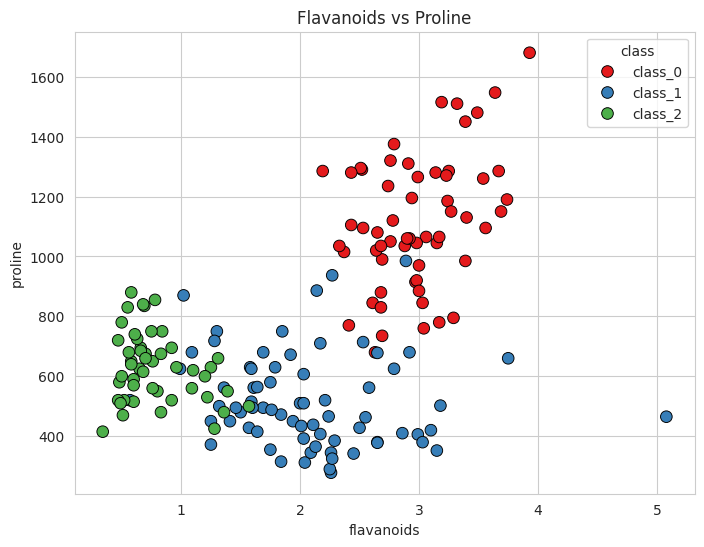

In [21]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='flavanoids', y='proline', hue='class',
                palette='Set1', s=70, edgecolor='k')
plt.title('Flavanoids vs Proline')
plt.show()

Creates a scatter plot to show the relationship between flavanoids and proline in wine.
Uses different colors to represent the three wine classes.
Displays the plot to compare the classes and identify patterns.

4 Covariance matrix


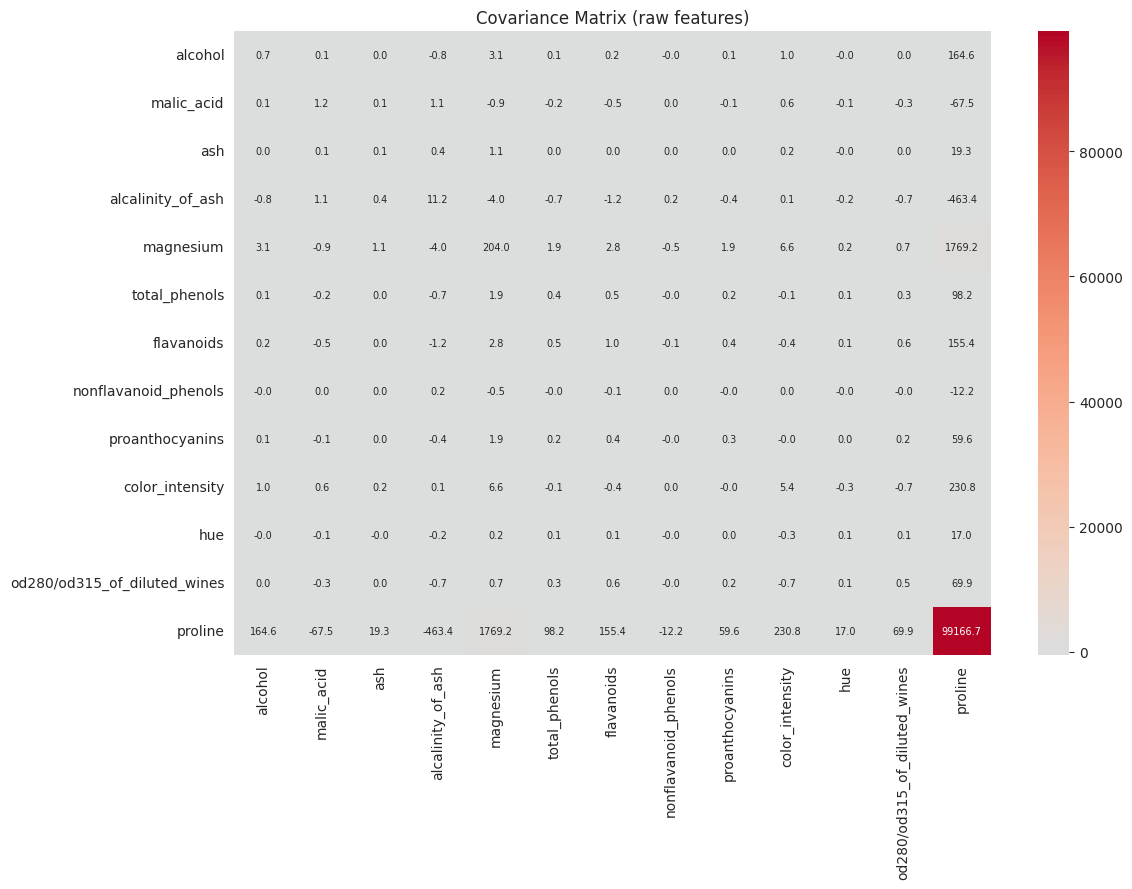

In [22]:
cov_matrix = df[features].cov()

plt.figure(figsize=(12, 9))
sns.heatmap(cov_matrix, annot=True, fmt='.1f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Covariance Matrix (raw features)')
plt.tight_layout()
plt.show()

Calculates the covariance matrix to show relationships between wine features.
Creates a heatmap with colors and values to visualize positive and negative covariance.
Displays the heatmap to compare how features vary together.

5 Data scaling

Scaled data: mean ~ 0, std ~ 1


,mean,std,min,max
alcohol,0.0,1.003,-2.434,2.260
malic_acid,0.0,1.003,-1.433,3.109
ash,-0.0,1.003,-3.679,3.156
alcalinity_of_ash,-0.0,1.003,-2.671,3.155
magnesium,-0.0,1.003,-2.088,4.371
total_phenols,-0.0,1.003,-2.107,2.540
flavanoids,0.0,1.003,-1.696,3.063
nonflavanoid_phenols,-0.0,1.003,-1.868,2.402
proanthocyanins,-0.0,1.003,-2.069,3.485
color_intensity,-0.0,1.003,-1.634,3.435


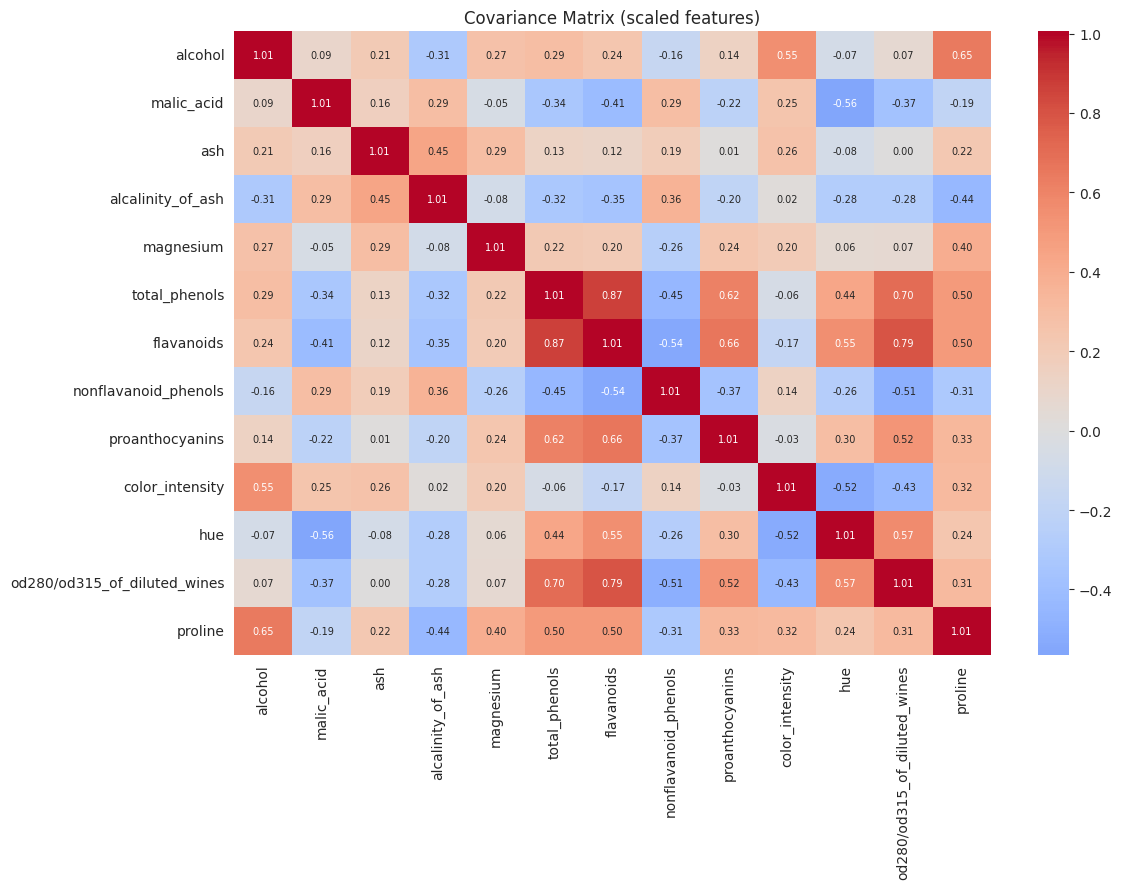

In [23]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
df_scaled = pd.DataFrame(X_scaled, columns=features)

print('Scaled data: mean ~ 0, std ~ 1')
display(df_scaled.describe().T[['mean', 'std', 'min', 'max']].round(3))

plt.figure(figsize=(12, 9))
sns.heatmap(df_scaled.cov(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Covariance Matrix (scaled features)')
plt.tight_layout()
plt.show()

Standardizes wine features so their mean is approximately 0 and standard deviation is 1.
Displays summary statistics of the scaled data.
Plots a heatmap of the covariance matrix to examine relationships between standardized features.

6 Class separation using principal components

Explained variance ratio: [0.362 0.192 0.111]
Total variance explained: 66.5%


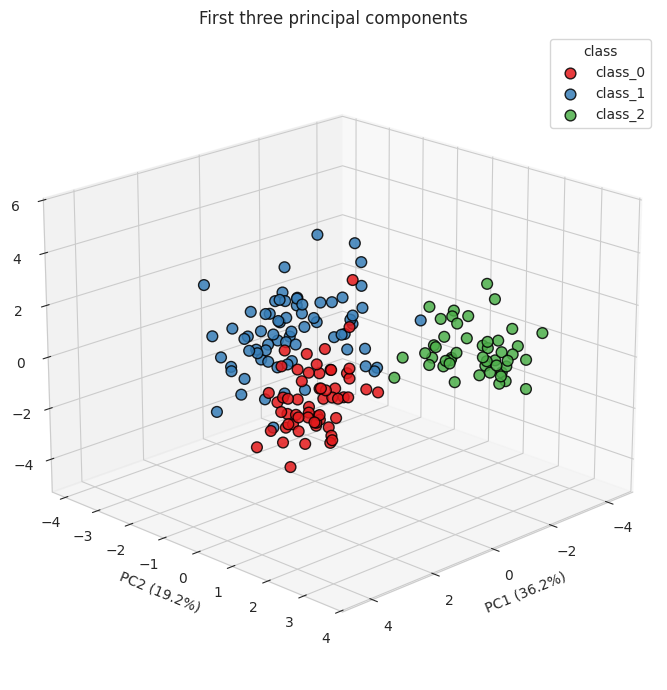

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA


pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print('Explained variance ratio:', pca.explained_variance_ratio_.round(3))
print('Total variance explained: %.1f%%' % (pca.explained_variance_ratio_.sum() * 100))

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3'])
pca_df['class'] = df['class']

classes = sorted(pca_df['class'].unique())
colors = sns.color_palette('Set1', len(classes))

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

for c, color in zip(classes, colors):
    sub = pca_df[pca_df['class'] == c]
    ax.scatter(sub['PC1'], sub['PC2'], sub['PC3'],
               label=c, color=color, s=60, edgecolor='k', alpha=0.85)

ax.set_title('First three principal components')
ax.set_xlabel('PC1 (%.1f%%)' % (pca.explained_variance_ratio_[0] * 100))
ax.set_ylabel('PC2 (%.1f%%)' % (pca.explained_variance_ratio_[1] * 100))
ax.set_zlabel('PC3 (%.1f%%)' % (pca.explained_variance_ratio_[2] * 100))
ax.legend(title='class')
ax.view_init(elev=20, azim=45)

plt.tight_layout()
plt.show()

Used PCA to reduce the scaled data into three principal components and calculated the variance explained by them and also created a 3D scatter plot using different colours for each class to visualize how the data is distributed and grouped.